<a href="https://colab.research.google.com/github/kunapareddysriram2007-cmyk/Deep_Learning/blob/main/VisionPort_Skill_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi

Tue Nov 10 03:28:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import torch

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

GPU Available: True
GPU Name: Tesla T4


In [ ]:
!pip install -q ultralytics

In [ ]:
import torch
import cv2
import matplotlib.pyplot as plt

from ultralytics import YOLO
from google.colab import files

print("GPU Available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU Available: True
GPU: Tesla T4


In [ ]:
model = YOLO("yolo11n.pt")

print("VisionPort model loaded successfully!")

VisionPort model loaded successfully!


In [ ]:
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print("Uploaded image:", image_path)

Saving traffic_image.jpg to traffic_image.jpg
Uploaded image: traffic_image.jpg


In [ ]:
results = model.predict(
    source=image_path,
    conf=0.25,
    device=0
)

print("Object detection completed!")


image 1/1 /content/traffic_image.jpg: 448x640 6 persons, 24 cars, 1 motorcycle, 1 bus, 1 truck, 8.4ms
Speed: 142.7ms preprocess, 8.4ms inference, 38.3ms postprocess per image at shape (1, 3, 448, 640)
Object detection completed!


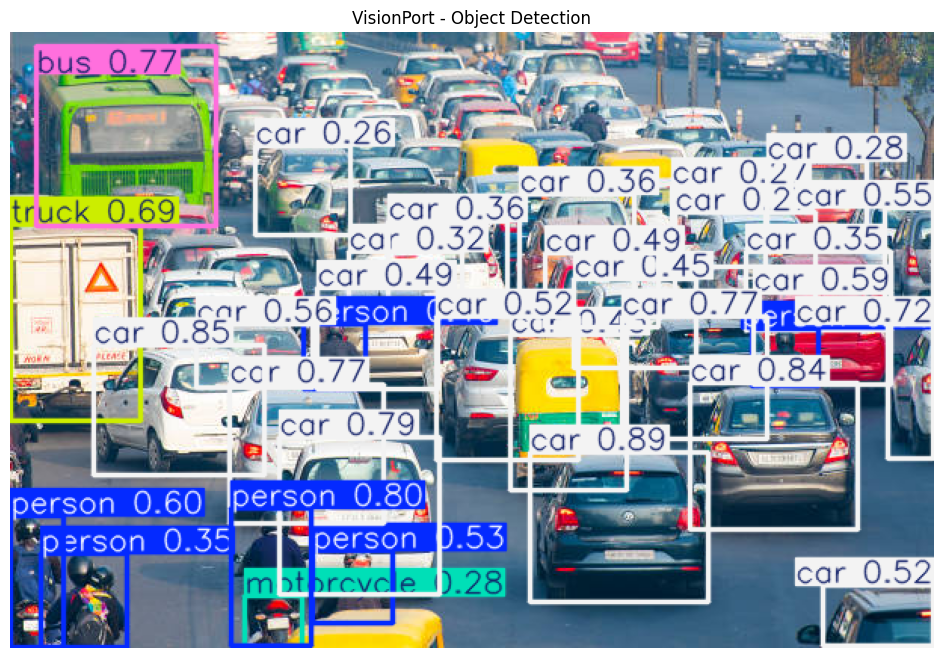

In [ ]:
result = results[0]

detected_image = result.plot()

detected_image = cv2.cvtColor(
    detected_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 8))
plt.imshow(detected_image)
plt.axis("off")
plt.title("VisionPort - Object Detection")
plt.show()

In [ ]:
for box in result.boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    object_name = result.names[class_id]

    print(
        f"Object: {object_name} | "
        f"Confidence: {confidence:.2%}"
    )

Object: car | Confidence: 88.92%
Object: car | Confidence: 84.87%
Object: car | Confidence: 84.44%
Object: person | Confidence: 79.76%
Object: car | Confidence: 78.70%
Object: car | Confidence: 77.21%
Object: car | Confidence: 77.03%
Object: bus | Confidence: 76.80%
Object: car | Confidence: 71.55%
Object: truck | Confidence: 69.21%
Object: person | Confidence: 59.53%
Object: car | Confidence: 58.91%
Object: car | Confidence: 55.96%
Object: car | Confidence: 55.04%
Object: person | Confidence: 52.95%
Object: car | Confidence: 52.50%
Object: car | Confidence: 51.75%
Object: car | Confidence: 48.97%
Object: car | Confidence: 48.52%
Object: car | Confidence: 45.12%
Object: car | Confidence: 42.90%
Object: person | Confidence: 40.12%
Object: car | Confidence: 36.31%
Object: person | Confidence: 36.14%
Object: car | Confidence: 35.54%
Object: car | Confidence: 35.30%
Object: person | Confidence: 34.71%
Object: car | Confidence: 32.35%
Object: motorcycle | Confidence: 28.46%
Object: car | Co